# TP Vision Transformer
---

## **Réalisé par :** Radouane Oubakhane

In [28]:
!pip install xmltodict

In [45]:
# For tips on running notebooks in Google Colab, see
# https://pytorch.org/tutorials/beginner/colab
%matplotlib inline

#from google.colab import drive
#drive.mount('/content/gdrive')

import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import xmltodict
import torch
from torch.utils.data import random_split
import torchvision
from torchvision.models import vit_b_16
from torchvision.io import decode_image
from torchvision.tv_tensors import BoundingBoxes
from torch.utils.data import Dataset
import sklearn.metrics as skm

from torchvision.transforms import v2

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

# uncomment if the data folder is not immediately visible (seems to be dependent on sessions...)
#os.listdir()
#os.chdir('gdrive/MyDrive')

img_dir='images'

# Example Images
example_imgs = ["images/Examples/catsNdogs.png"]

# capture activation layers with hooks
activation = {}

def get_activation(name):
    def hook(model, input, output):
        if isinstance(output, tuple):
            activation[name] = [o.detach() for o in output]
        else:
            activation[name] = output.detach()
    return hook


Using cuda device


## Lecture des données

In [46]:
# Read ImageNet categories
with open("images/imagenet_classes.txt", "r") as f:
    imagenet_cat = [s.strip() for s in f.readlines()]

In [47]:
# data set for Oxford data
def read_filenames(list_f,img_dir,annot_dir):
    with open(list_f, "r") as f:
        lines = [s.strip().split() for s in f.readlines() if s[0] != '#']
        
    ret=[]
    for l in lines:
        name=l[0]
        iname=os.path.join(img_dir, f'{name}.jpg')
        aname=os.path.join(annot_dir, f'{name}.xml')
        if os.path.isfile(iname) and os.path.isfile(aname):
            ret.append({'fname':name,'category':int(l[1])-1}) # -1 to start at 0
    return ret

class MyDataset(Dataset):
    def __init__(self, base_dir, split='trainval',transform=None, target_transform=None):
        data_dir=f'{base_dir}/oxford-iiit-pet'
        self.annot_dir = f'{data_dir}/annotations/xmls'
        self.img_dir = f'{data_dir}/images'
        if split=='test':
            list_f=f'{data_dir}/annotations/split.txt'
        else:
            list_f=f'{data_dir}/annotations/trainval.txt'
        self.fnames=read_filenames(list_f,self.img_dir,self.annot_dir)
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.fnames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, f"{self.fnames[idx]['fname']}.jpg")
        image = Image.open(img_path)
        xml_path=os.path.join(self.annot_dir, f"{self.fnames[idx]['fname']}.xml")
        with open(xml_path,'r') as f:
            d=xmltodict.parse(f.read())
            img_size=d['annotation']['size']
            obj=d['annotation']['object']
            if not type(obj) is list:
                obj=[obj]
            bb=[[int(o['bndbox']['xmin']),int(o['bndbox']['ymin']),int(o['bndbox']['xmax']),int(o['bndbox']['ymax'])] for o in obj]
            bb=BoundingBoxes(bb,format='XYXY',canvas_size=[int(img_size['width']),int(img_size['height'])])
        l=self.fnames[idx]['category']
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            bb = self.target_transform(bb)
        return image, {'bndbox':bb,'category':l}

In [48]:
# Load Oxford pet data
download=True # set to False if the dataset has already been downloaded
target_types='category'
pet_data = torchvision.datasets.OxfordIIITPet(img_dir,download=download)
test_data= torchvision.datasets.OxfordIIITPet(img_dir,download=download, split='test')
vit_preprocess=v2.Compose([
    v2.Resize((224,224)),
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True)
])
pet_data=MyDataset(img_dir,transform=vit_preprocess,target_transform=vit_preprocess)
test_data=MyDataset(img_dir,transform=vit_preprocess,target_transform=vit_preprocess)

In [49]:
# Generate train/validation/test datasets
batch_size=4
generator = torch.Generator()
s=random_split(pet_data, [0.8, 0.2], generator=generator)

train_loader = torch.utils.data.DataLoader(torch.utils.data.Subset(pet_data, s[0].indices),
                                          batch_size=batch_size,
                                          shuffle=True,
                                          num_workers=1,
                                          collate_fn=lambda batch: (torch.stack([dp[0] for dp in batch]),[dp[1] for dp in batch]))

# count number of train data
n_train=0
for imgs, label in train_loader:
    n_train += len(label)
    
val_loader = torch.utils.data.DataLoader(torch.utils.data.Subset(pet_data, s[1].indices),
                                         batch_size=batch_size,
                                         collate_fn=lambda batch: (torch.stack([dp[0] for dp in batch]),[dp[1] for dp in batch]))

# count number of validation data
n_val=0
for imgs, label in val_loader:
    n_val += len(label)


test_loader=torch.utils.data.DataLoader(test_data,
                                        batch_size=batch_size,
                                        collate_fn=lambda batch: (torch.stack([dp[0] for dp in batch]),[dp[1] for dp in batch]))
# count number of test data
n_test=0
for imgs, label in test_loader:
    n_test += len(label)

print(f'Dataset sizes: train={n_train}, validation={n_val}, test={n_test}') 

Dataset sizes: train=2937, validation=734, test=3671


In [50]:
# read out Oxford categories
with open(f"{img_dir}/oxford-iiit-pet/annotations/list.txt", "r") as f:
    lines = [s.strip().split() for s in f.readlines() if s[0] != '#']
    labels = np.unique(np.array([l[1] for l in lines]),return_index=True)[1]
    oxford_cat = [0]*len(labels)
    for i in labels:
        idx=int(lines[i][1])-1
        name=' '.join(lines[i][0].split('_')[:-1])
        oxford_cat[idx]= name
#display
[l for l in enumerate(oxford_cat)]

[(0, 'Abyssinian'),
 (1, 'american bulldog'),
 (2, 'american pit bull terrier'),
 (3, 'basset hound'),
 (4, 'beagle'),
 (5, 'Bengal'),
 (6, 'Birman'),
 (7, 'Bombay'),
 (8, 'boxer'),
 (9, 'British Shorthair'),
 (10, 'chihuahua'),
 (11, 'Egyptian Mau'),
 (12, 'english cocker spaniel'),
 (13, 'english setter'),
 (14, 'german shorthaired'),
 (15, 'great pyrenees'),
 (16, 'havanese'),
 (17, 'japanese chin'),
 (18, 'keeshond'),
 (19, 'leonberger'),
 (20, 'Maine Coon'),
 (21, 'miniature pinscher'),
 (22, 'newfoundland'),
 (23, 'Persian'),
 (24, 'pomeranian'),
 (25, 'pug'),
 (26, 'Ragdoll'),
 (27, 'Russian Blue'),
 (28, 'saint bernard'),
 (29, 'samoyed'),
 (30, 'scottish terrier'),
 (31, 'shiba inu'),
 (32, 'Siamese'),
 (33, 'Sphynx'),
 (34, 'staffordshire bull terrier'),
 (35, 'wheaten terrier'),
 (36, 'yorkshire terrier')]

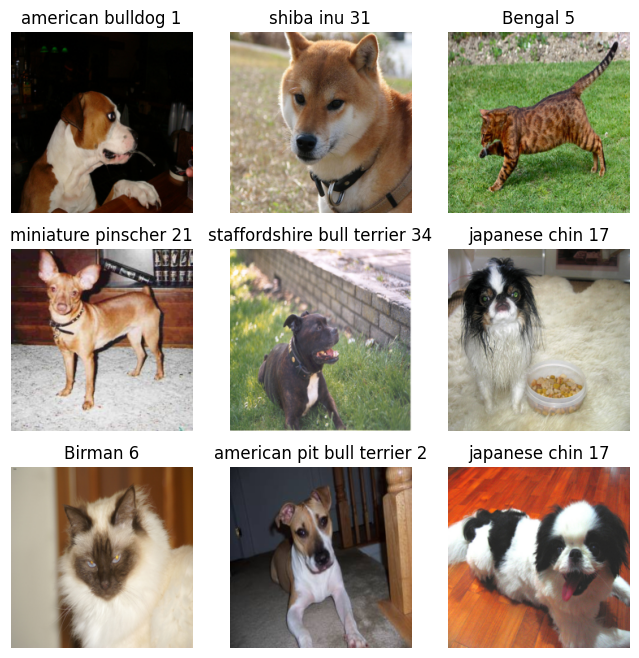

In [51]:
# display samples of the database
plt.close('all')
cols, rows = 3, 3
sample_idx = torch.randint(len(pet_data), size=(cols*rows,))
figure = plt.figure(figsize=(8, 8))
img, label = pet_data[0]
for i in range(cols*rows):
    idx=sample_idx[i]
    img, label = pet_data[idx]
    l=label['category']
    figure.add_subplot(rows, cols, i+1)
    plt.title(f'{oxford_cat[l]} {l}')
    plt.axis("off")
    plt.imshow(img.numpy().transpose([1,2,0]))

# Vision Transformer Model

In [52]:
# vision transformer model
vit_model = vit_b_16(weights='IMAGENET1K_V1')
print(vit_model)

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [53]:
# test inference on example_imgs[0]
# capture activations
vit_model.conv_proj.register_forward_hook(get_activation('conv_proj'))
vit_model.encoder.layers.encoder_layer_0.ln_1.register_forward_hook(get_activation('enc_0_ln_1'))
vit_model.encoder.ln.register_forward_hook(get_activation('ln'))
vit_model.encoder.layers.encoder_layer_8.self_attention.out_proj.register_forward_hook(get_activation('enc_8_sa'))

# test classification with ViT on catsNdogs
input_image = Image.open(example_imgs[0])
input_tensor = vit_preprocess(input_image)
input_batch = input_tensor.unsqueeze(0) # create a mini-batch as expected by the model

# move the input and model to GPU for speed if available
input_batch = input_batch.to(device)
vit_model.to(device)

# use model in eval mode to avoid gradient computations
vit_model.eval()
with torch.no_grad():
    # Tensor of shape 1000, with confidence scores over ImageNet's 1000 classes
    output = vit_model(input_batch)

# The output has unnormalized scores. To get probabilities, you can run a softmax on it.
probabilities = torch.nn.functional.softmax(output[0], dim=0)

# Show top categories per image
top5_prob, top5_catid = torch.topk(probabilities, 5)
for i in range(top5_prob.size(0)):
    print(imagenet_cat[top5_catid[i]], top5_prob[i].item())

tabby 0.08697682619094849
cleaver 0.041564978659152985
Border collie 0.041473038494586945
tiger cat 0.033729467540979385
letter opener 0.017116840928792953


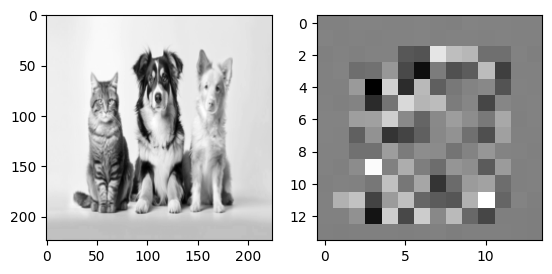

In [54]:
# show example activations
conv_feat=700
ima=activation['conv_proj'][0,conv_feat,:,:].cpu().numpy()
# uncomment for encoder outputs
#enc_size=(14,14)
#ima=activation['enc_0_ln_1'][0,1:,3].cpu().numpy().reshape(enc_size) 
fig,(ax0,ax1)=plt.subplots(1,2)
ax0.imshow(input_tensor[0].cpu().numpy(),cmap='gray')
ax1.imshow(ima,cmap='gray')

# Questions notées

## Question 1
**Faites l’inférence sur toutes les images de la base de test, et calculez la classe la plus probable associée à chaque image dans cette base par le modèle.**

In [59]:
# On passe le modèle en mode évaluation 
vit_model.eval()

# Listes pour stocker les résultats
predictions_imagenet = [] # Les classes prédites par le modèle 
vrais_labels_oxford = []  # Les vraies classes du dataset Oxford 

print("Lancement de l'inférence sur la base de test")
print("-" * 30)

# On désactive le calcul du gradient car on ne fait pas d'apprentissage ici
with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        # On envoie les image sur le gpu 
        inputs = inputs.to(device)
        
        
        outputs = vit_model(inputs)
        
        # On récupère l'indice de la classe qui a la plus grande probabilité
        _, preds = torch.max(outputs, 1)
        
        # On ajoute les prédictions à notre liste 
        predictions_imagenet.extend(preds.cpu().numpy())
        
        # les vrais labels 
        current_labels = [t['category'] for t in targets]
        vrais_labels_oxford.extend(current_labels)
        
        # affichage pour suivre l'avancement 
        if batch_idx % 100 == 0:
            print(f"Batch {batch_idx} traité")

print("-" * 30)

premier_pred = predictions_imagenet[0]
premier_vrai = vrais_labels_oxford[0]

# Exemple image 0
print(f"Exemple : classe prédite ImageNet = {premier_pred} ({imagenet_cat[premier_pred]}) | Vraie classe Oxford = {premier_vrai} ({oxford_cat[premier_vrai]})")

Lancement de l'inférence sur la base de test
------------------------------
Batch 0 traité
Batch 100 traité
Batch 200 traité
Batch 300 traité
Batch 400 traité
Batch 500 traité
Batch 600 traité
Batch 700 traité
Batch 800 traité
Batch 900 traité
------------------------------
Exemple : classe prédite ImageNet = 750 (quilt) | Vraie classe Oxford = 0 (Abyssinian)


Mauvaise prédiction: **quilt** au lieu de **Abyssinian**

## Question 2
**Identifiez la catégorie d’ImageNet la plus souvent associée à chaque catégorie d’Oxford, ainsi que la proportion dans laquelle chaque correspondance se réalise. Qu’en déduisez-vous ? On appelle "catégories restreintes" le sous-ensemble des catégories d’ImageNet ainsi identifié.**

In [56]:
# Convertir les listes en tableaux numpy pour faciliter les manipulations
preds_arr = np.array(predictions_imagenet)
labels_arr = np.array(vrais_labels_oxford)

# Liste pour stocker les indices des catégories ImageNet identifiées (pour la suite)
categories_restreintes = []

print(f"{'Catégorie Oxford':<30} | {'Catégorie ImageNet dominante':<30} | {'Proportion':<10}")
print("-" * 80)

# On parcourt les 37 catégories d'Oxford
for i in range(37):
    # 1. On récupère toutes les prédictions faites pour les images de la classe Oxford 'i'
    indices_images_classe_i = (labels_arr == i)
    predictions_pour_classe_i = preds_arr[indices_images_classe_i]
    
    if len(predictions_pour_classe_i) == 0:
        continue

    # 2. On cherche la valeur la plus fréquente (le mode)
    # np.bincount compte le nombre d'occurrences de chaque valeur
    comptes = np.bincount(predictions_pour_classe_i)
    classe_imagenet_top = np.argmax(comptes)
    
    # 3. On calcule la proportion
    nb_occurences = comptes[classe_imagenet_top]
    total_images = len(predictions_pour_classe_i)
    proportion = nb_occurences / total_images
    
    # 4. On stocke cette classe ImageNet
    if classe_imagenet_top not in categories_restreintes:
        categories_restreintes.append(classe_imagenet_top)
    
    # Affichage
    nom_oxford = oxford_cat[i]
    nom_imagenet = imagenet_cat[classe_imagenet_top]
    # On tronque les noms trop longs pour l'affichage
    print(f"{nom_oxford:<30} | {nom_imagenet:<30} | {proportion:.1%}")

print("-" * 80)
print(f"Nombre de catégories ImageNet identifiées (catégories restreintes) : {len(categories_restreintes)}")

Catégorie Oxford               | Catégorie ImageNet dominante   | Proportion
--------------------------------------------------------------------------------
Abyssinian                     | Egyptian cat                   | 73.7%
american bulldog               | boxer                          | 42.0%
american pit bull terrier      | American Staffordshire terrier | 64.0%
basset hound                   | basset                         | 89.0%
beagle                         | beagle                         | 62.0%
Bengal                         | Egyptian cat                   | 69.4%
Birman                         | Siamese cat                    | 76.0%
Bombay                         | Egyptian cat                   | 69.8%
boxer                          | boxer                          | 77.0%
British Shorthair              | Egyptian cat                   | 52.0%
chihuahua                      | Chihuahua                      | 71.0%
Egyptian Mau                   | Egyptian cat     

## Analyse

**Observation :**
À partir du tableau de correspondances généré, nous pouvons faire plusieurs constats importants :

1.  **Excellente reconnaissance pour certaines races :**
    Le modèle identifie avec une très grande précision certaines races spécifiques qui existent à la fois dans Oxford et ImageNet.
    * Exemples : Persian (100%), Siamese (99.0%), Pug (98.0%), Saint Bernard (91.9%).
    * Cela confirme que les caractéristiques visuelles de ces animaux ont été parfaitement apprises lors du pré-entraînement sur ImageNet.

2.  **Manque de distinction pour les chats :**
    On remarque que la classe Egyptian cat absorbe la majorité des races de chats (Abyssinian, Bengal, Bombay, Sphynx...). Le modèle ne parvient pas à différencier ces races spécifiques et leur attribue à toutes cette même étiquette par défaut.

3.  Le modèle fait des erreurs qui sont faciles à comprendre car les animaux se ressemblent beaucoup, comme l'American Pit Bull Terrier et American Staffordshire terrier

   
**Conclusion :**
Le modèle sait déjà reconnaître la plupart des animaux grâce à son pré-entraînement sur ImageNet. Cependant, comme les listes de classes ne sont pas identiques, il associe les races inconnues à ce qui leur ressemble le plus visuellement.
Les 37 classes d'Oxford se projettent sur un sous-ensemble plus petit de 28 catégories ImageNet.

## Question 3
**L’article de Vision Transformer ne mentionne aucune fonction de perte. Quelle fonction de perte est la plus appropriée selon vous ?**

Pour notre problème de classification multi-classes, il y a 37 races différentes et une seule bonne réponse par image, la fonction de perte la plus appropriée est l'Entropie Croisée.

## Question 4
**Les catégories d'ImageNet associées à au moins une catégorie d'Oxford forment un sous-ensemble des catégories d'ImageNet. On veut calculer la fonction de perte en ne considérant que les catégories restreintes. Proposez une ou plusieurs manières de faire et faites le(s) calcul(s). Qu'en déduisez-vous ?**

**Méthodes :**

### Méthode 1 : Loss sur 1000 classes avec mapping Oxford vers ImageNet
- Utiliser la correspondance statistique établie précédemment
- Traduire chaque label Oxford en label ImageNet dominant
- Calculer la CrossEntropyLoss sur les 1000 sorties

### Méthode 2 : Loss sur catégories restreintes uniquement (28 classes)
- Extraire seulement les 28 logits correspondant aux catégories restreintes
- Recalculer le softmax sur ce sous-ensemble
- Calculer la loss sur ces 28 classes uniquement

**Avantage Méthode 2 :** Le softmax est recalculé sur 28 classes au lieu de 1000, ce qui donne des probabilités plus élevées et une évaluation plus juste de la capacité du modèle à distinguer les catégories pertinentes.

In [63]:
# création du mapping oxford vers imageNet
mapping_oxford_to_imagenet = {}
for i in range(37):
    indices = (labels_arr == i)
    if np.sum(indices) > 0:
        classe_dominante = np.argmax(np.bincount(preds_arr[indices]))
        mapping_oxford_to_imagenet[i] = classe_dominante

# Mapping ImageNet to index restreint 
imagenet_to_restricted = {cat: idx for idx, cat in enumerate(categories_restreintes)}

# Définir la loss
criterion = torch.nn.CrossEntropyLoss()
vit_model.eval()

# =============================================================================


# Méthode 1
print("Méthode 1: Loss sur 1000 classes ImageNet")

loss_method1 = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        labels_oxford = [t['category'] for t in targets]
        
        # Convertir oxford vers imageNet
        target_imagenet = torch.tensor([mapping_oxford_to_imagenet[l] for l in labels_oxford]).to(device)
        
        outputs = vit_model(inputs) 
        loss = criterion(outputs, target_imagenet)
        
        loss_method1 += loss.item() * inputs.size(0)
        count += inputs.size(0)

loss_method1 = loss_method1 / count
print(f"Loss moyenne - Méthode 1: {loss_method1:.4f}")

# =============================================================================

print("-" * 50)

# Méthode 2

print("\nMéthode 2: Loss sur 28 catégories restreintes")

loss_method2 = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        labels_oxford = [t['category'] for t in targets]
        
        # convertir Oxford vers index restreint (
        target_restricted = []
        for l in labels_oxford:
            imagenet_class = mapping_oxford_to_imagenet[l]
            restricted_idx = imagenet_to_restricted[imagenet_class]
            target_restricted.append(restricted_idx)
        target_restricted = torch.tensor(target_restricted).to(device)
        
        outputs = vit_model(inputs)
        # extraire les 28 logits restreints
        outputs_restricted = outputs[:, categories_restreintes]
        
        loss = criterion(outputs_restricted, target_restricted)
        loss_method2 += loss.item() * inputs.size(0)
        count += inputs.size(0)

loss_method2 = loss_method2 / count
print(f"Loss moyenne (Méthode 2): {loss_method2:.4f}")


# =============================================================================

# Comparaison des méthode

print("\n" + "=" * 50)
print("Comparaison des méthode")
print("=" * 50)
print(f"Méthode 1 :  Loss = {loss_method1:.4f}")
print(f"Méthode 2 :    Loss = {loss_method2:.4f}")
print(f"Différence:                {loss_method1 - loss_method2:.4f}")
print("=" * 50)

Méthode 1: Loss sur 1000 classes ImageNet
Loss moyenne - Méthode 1: 1.9201
--------------------------------------------------

Méthode 2: Loss sur 28 catégories restreintes
Loss moyenne (Méthode 2): 0.4054

Comparaison des méthode
Méthode 1 :  Loss = 1.9201
Méthode 2 :    Loss = 0.4054
Différence:                1.5146


## Conclusion 

* La méthode 1 avec les 1000 classes donne une perte de 1.9201, tandis que la méthode 2 avec les 28 classes restreintes donne une perte de 0.4054.

* On observe une chute importante de la perte car la première méthode divise la probabilité du softmax sur 1000 classes, alors que la seconde la limite à 28 classes seulement, avec moins de classes, les probabilités sont plus concentrées sur la bonne réponse.

* Le modèle sait déjà très bien distinguer visuellement les animaux, car une perte de 0.40 est excellente. Le problème ne vient pas des capacités visuelles du modèle, mais simplement du fait qu'il possède trop de vocabulaire inutile pour notre tâche.

## Question 5
**Proposez une adaptation possible du modèle Vision Transformer afin de l'entrainer à reconnaitre les catégories d'Oxford. Justifiez et critiquez votre choix.**

### Adaptation proposée : Remplacer la dernière couche 

Le modèle original a une couche de sortie avec 1000 neurones, on la remplace par une couche avec 37 neurones

### Justification :
1. On garde toutes les features apprises sur ImageNet
2. Les couches profondes savent déjà extraire des features visuelles
3. On entraîne seulement la nouvelle couche avec moins de paramètres

### Critique :
- Entraînement rapide et peu de données nécessaires
- Comme on ne modifie pas la partie principale du réseau, on garde ses défauts d'origine.

## Question 6 : Ré-apprentissage et Résultats

**Justification des hyperparamètres :**


* **Optimiseur :** Nous utilisons adam, car adam converge généralement plus vite, ce qui est idéal pour une convergence rapide en 5 époques.
* **Learning Rate (1e-4) :** Un taux prudent pour assurer une descente de gradient stable.
* **5 Époques :** Suffisant car nous n'avons qu'une seule couche linéaire à entraîner.

Calcul de la loss initiale
Loss initiale : 3.7012

Début de l'entraînement (5 époques)
Epoch 1/5 | Train Loss: 2.5221 | Val Loss: 1.5945
Epoch 2/5 | Train Loss: 1.0959 | Val Loss: 0.8422
Epoch 3/5 | Train Loss: 0.6434 | Val Loss: 0.5972
Epoch 4/5 | Train Loss: 0.4677 | Val Loss: 0.4834
Epoch 5/5 | Train Loss: 0.3731 | Val Loss: 0.4149

Calcul de la loss finale
Loss finale : 0.3439



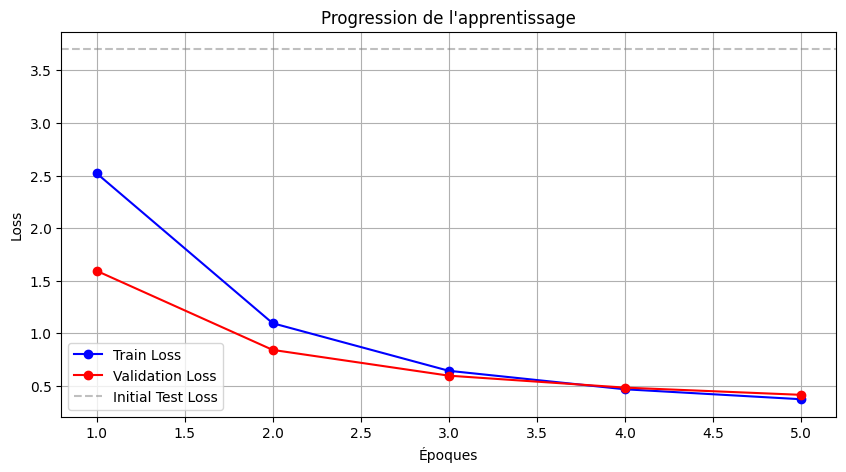


Évaluation sur datasets de Test
Loss initiale : 3.7012
Loss finale   : 0.3439
Amélioration  : 3.3573 (90.7%)


In [71]:
import torch.nn as nn
import torch.optim as optim

# Recharger le modèle 
vit_model_finetuned = vit_b_16(weights='IMAGENET1K_V1')

# geler les couches 
for param in vit_model_finetuned.parameters():
    param.requires_grad = False

# Remplacer la tête de classification, de 1000 vers 37 classes
num_classes_oxford = 37
vit_model_finetuned.heads = nn.Linear(vit_model_finetuned.heads[0].in_features, num_classes_oxford)

vit_model_finetuned = vit_model_finetuned.to(device)

# Hyperparamètres et Optimiseur

learning_rate = 1e-4
epochs = 5
criterion = nn.CrossEntropyLoss()

# On optimise uniquement les paramètres de la tête 
optimizer = optim.Adam(vit_model_finetuned.heads.parameters(), lr=learning_rate)

# Calcul de la loss initiale
print("=" * 50)
print("Calcul de la loss initiale")
print("=" * 50)

# Mode évaluation
vit_model_finetuned.eval() 
initial_loss = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        labels = torch.tensor([t['category'] for t in targets]).to(device)
        
        outputs = vit_model_finetuned(inputs)
        loss = criterion(outputs, labels)
        
        initial_loss += loss.item() * inputs.size(0)
        count += inputs.size(0)

initial_loss = initial_loss / count
print(f"Loss initiale : {initial_loss:.4f}\n")

# 4. Entraînement 

print("=" * 50)
print(f"Début de l'entraînement ({epochs} époques)")
print("=" * 50)

train_losses = []
val_losses = []

for epoch in range(epochs):
    # entraînement 
    vit_model_finetuned.train()
    running_loss = 0.0
    count = 0
    
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs = inputs.to(device)
        labels = torch.tensor([t['category'] for t in targets]).to(device)
        
        optimizer.zero_grad()
        outputs = vit_model_finetuned(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        count += inputs.size(0)
    
    epoch_train_loss = running_loss / count
    train_losses.append(epoch_train_loss)
    
    # validation
    vit_model_finetuned.eval()
    val_loss = 0.0
    count = 0
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            labels = torch.tensor([t['category'] for t in targets]).to(device)
            
            outputs = vit_model_finetuned(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            count += inputs.size(0)
    
    epoch_val_loss = val_loss / count
    val_losses.append(epoch_val_loss)
    
    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

# 5. Calcul de la loss finale

print("\n" + "=" * 50)
print("Calcul de la loss finale")
print("=" * 50)

vit_model_finetuned.eval()
final_loss = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        labels = torch.tensor([t['category'] for t in targets]).to(device)
        
        outputs = vit_model_finetuned(inputs)
        loss = criterion(outputs, labels)
        
        final_loss += loss.item() * inputs.size(0)
        count += inputs.size(0)

final_loss = final_loss / count
print(f"Loss finale : {final_loss:.4f}")
print("\n" + "=" * 50)

# 6. Visualisation

plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs+1), train_losses, 'b-o', label='Train Loss')
plt.plot(range(1, epochs+1), val_losses, 'r-o', label='Validation Loss')
plt.axhline(y=initial_loss, color='gray', linestyle='--', alpha=0.5, label='Initial Test Loss')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.title('Progression de l\'apprentissage')
plt.legend()
plt.grid(True)
plt.show()

print("\n" + "=" * 50)
print("Évaluation sur datasets de Test")
print("=" * 50)
print(f"Loss initiale : {initial_loss:.4f}")
print(f"Loss finale   : {final_loss:.4f}")
amelioration = initial_loss - final_loss
pourcentage = (amelioration / initial_loss) * 100
print(f"Amélioration  : {amelioration:.4f} ({pourcentage:.1f}%)")
print("=" * 50)

## Analyse des résultats

* La perte commence à 3.70, ce qui est normal pour le début, et le graphique montre qu'elle descend très vite dès le début grâce au pré-entraînement.

* Les courbes d'entraînement et de validation restent proches jusqu'à atteindre un score de 0.34, ce qui est meilleur que la méthode précédente et prouve que le modèle a bien appris.

## Question 7 : Choix des métriques

* **Accuracy :** C'est le pourcentage total de bonnes réponses, ce qui permet d'avoir une vue d'ensemble rapide et simple de la performance du modèle.

* **F1-Score :** Cette métrique calcule la moyenne de la réussite par classe, ce qui est utile pour vérifier que le modèle reconnait bien toutes les races et pas seulement les plus faciles.

* **Matrice de Confusion :** C'est un tableau qui montre quelles races sont confondues entre elles, ce qui permet de voir précisément les erreurs spécifiques du modèle.

In [77]:
import sklearn.metrics as skm


# Modèle non entraîné
vit_before = vit_b_16(weights='IMAGENET1K_V1')
vit_before.heads = torch.nn.Linear(vit_before.heads[0].in_features, 37)
vit_before = vit_before.to(device)
vit_before.eval()

y_true = []
y_pred_before = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        labels = [t['category'] for t in targets]
        outputs = vit_before(inputs)
        _, preds = torch.max(outputs, 1)
        
        y_true.extend(labels)
        y_pred_before.extend(preds.cpu().numpy())

# Modèle entraîné
vit_model_finetuned.eval()
y_pred_after = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = vit_model_finetuned(inputs)
        _, preds = torch.max(outputs, 1)
        y_pred_after.extend(preds.cpu().numpy())

# Affichage des métriques

print("\n" + "=" * 50)
print(f"{'MÉTRIQUE':<25} | {'AVANT':<10} | {'APRÈS':<10} | {'GAIN':<10}")
print("=" * 50)

# Accuracy
acc_before = skm.accuracy_score(y_true, y_pred_before)
acc_after = skm.accuracy_score(y_true, y_pred_after)
print(f"{'Accuracy':<25} | {acc_before:.4f}     | {acc_after:.4f}     | {acc_after-acc_before:+.4f}")

# F1-Score (Macro)
f1_before = skm.f1_score(y_true, y_pred_before, average='macro', zero_division=0)
f1_after = skm.f1_score(y_true, y_pred_after, average='macro', zero_division=0)
print(f"{'F1-Score - Macro':<25} | {f1_before:.4f}     | {f1_after:.4f}     | {f1_after-f1_before:+.4f}")
print("=" * 50)


MÉTRIQUE                  | AVANT      | APRÈS      | GAIN      
Accuracy                  | 0.0174     | 0.9365     | +0.9191
F1-Score - Macro          | 0.0146     | 0.9361     | +0.9216


## Analyse des performances

* Au début, l'accuracy est très basse (1.74%), ce qui est tout à fait normal avant l'entraînement.

* Après 5 époques, le score monte à 93.65%, ce qui prouve que le ré-apprentissage est efficace pour ce type de problème.

* De plus, le F1-Score (93.61%) est presque identique à l'accuracy, ce qui montre que le modèle reconnait bien toutes les races de manière équilibrée, sans négliger les plus difficiles.

## Question 8
**À la base de plusieurs métriques, se trouve la matrice de confusion. Calculez cette matrice avant et après apprentissage. Commentez le résultat.**

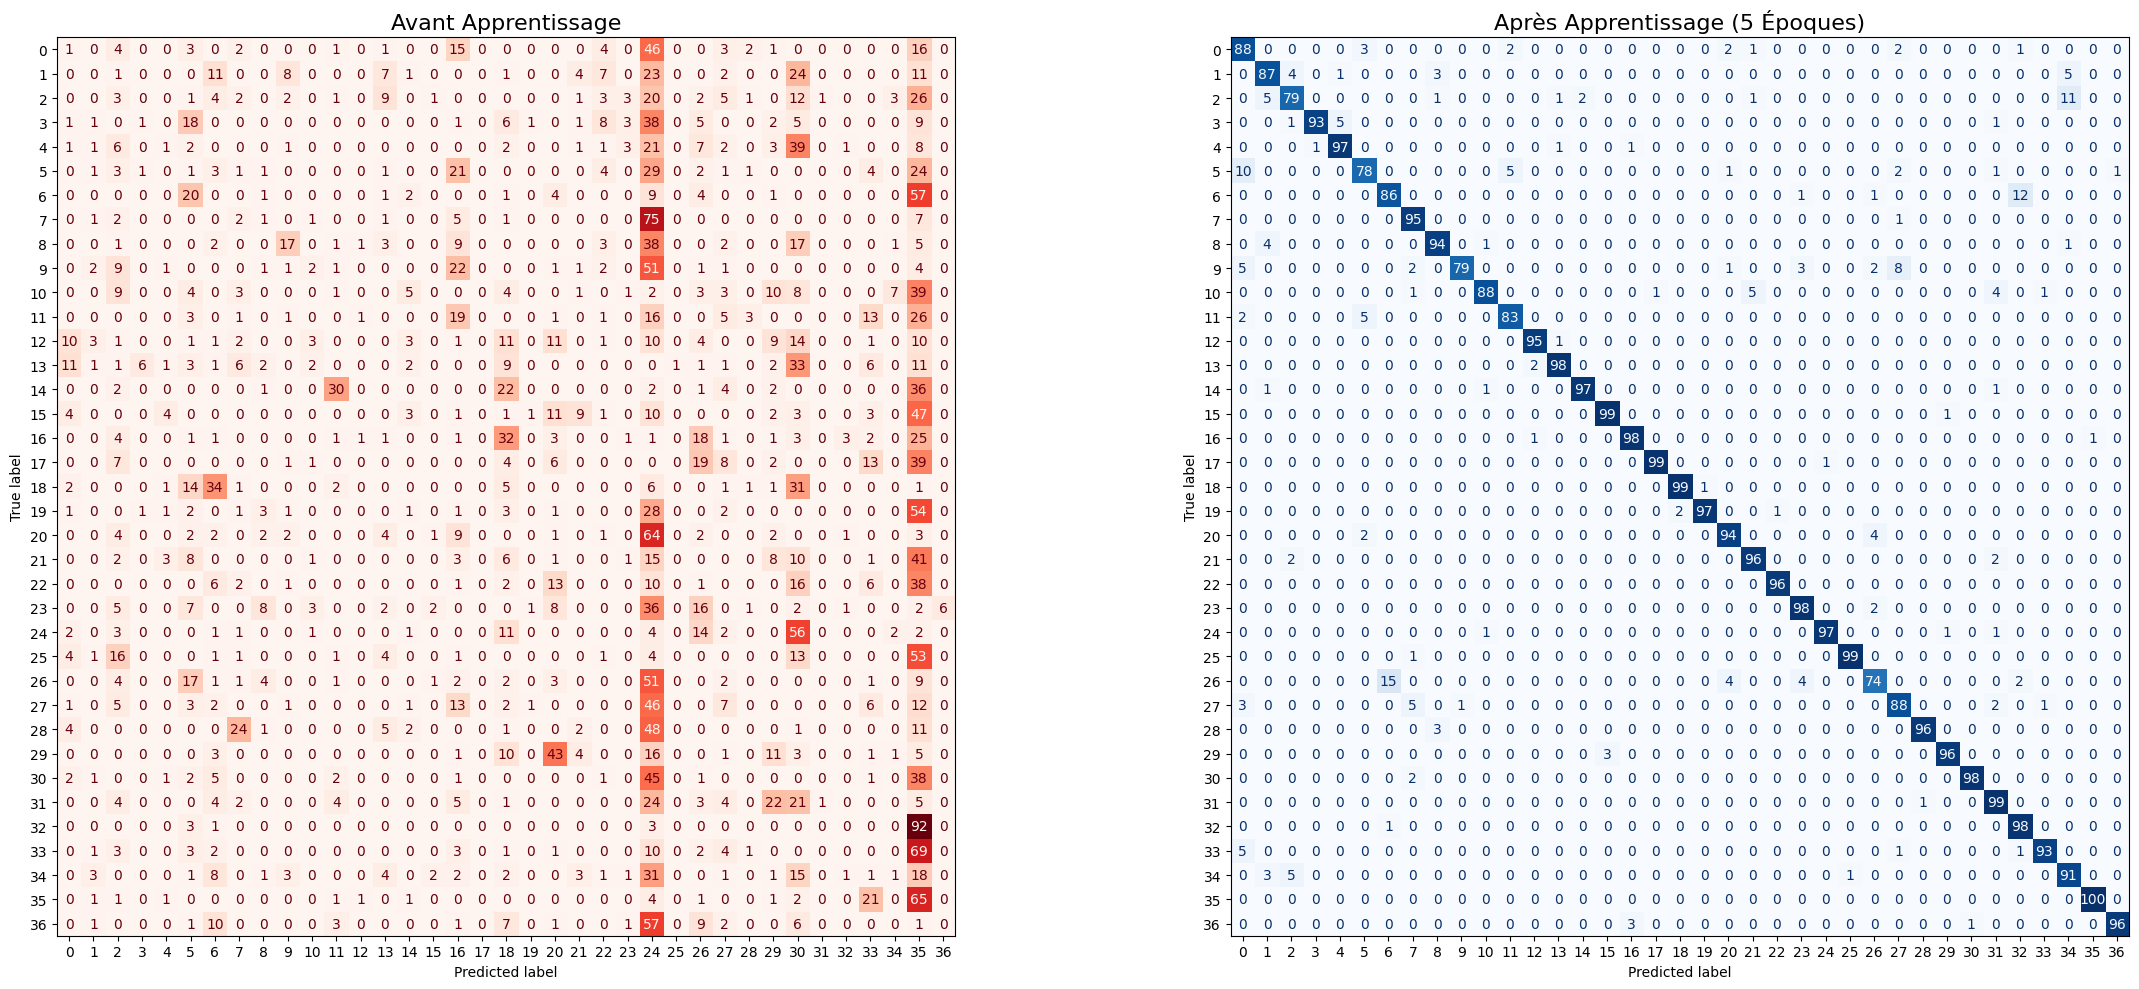

In [82]:
from sklearn.metrics import ConfusionMatrixDisplay

# Création d'une figure avec 2 graphiques 
fig, ax = plt.subplots(1, 2, figsize=(24, 10))

# Matrice avant 
ConfusionMatrixDisplay.from_predictions(
    y_true, 
    y_pred_before, 
    ax=ax[0], 
    colorbar=False,
    cmap='Reds' 
)
ax[0].set_title("Avant Apprentissage", fontsize=16)
ax[0].grid(False)

# 2. Matrice après 
ConfusionMatrixDisplay.from_predictions(
    y_true, 
    y_pred_after, 
    ax=ax[1], 
    colorbar=False,
    cmap='Blues'
)
ax[1].set_title("Après Apprentissage (5 Époques)", fontsize=16)
ax[1].grid(False)

plt.tight_layout()
plt.show()

## Analyse de la Matrice de Confusion

* **Avant :** Les points sont partout, ce qui prouve que le modèle répondait complètement au hasard avant d'apprendre.

* **Après :** Une diagonale nette apparaît, montrant que le modèle a presque tout le temps raison. Cependant, quelques valeurs hors de la diagonale restent visibles : elles représentent les rares erreurs où le modèle confond encore deux races très ressemblantes.

**Conclusion :** En 5 époques, le modèle est passé de l'ignorance totale à une excellente précision.

## Question 9 : Détection d'Objets 

### a - Adaptation de l'architecture
Pour prédire la boîte englobante, nous transformons le problème de classification en problème de régression.
Nous remplaçons la tête du Vision Transformer par un Perceptron Multicouche (MLP) composé de :
1.  Une couche linéaire (768 $\to$ 256) avec activation ReLU pour extraire des features géométriques.
2.  Une couche de sortie (256 $\to$ 4) pour les coordonnées $(x_{min}, y_{min}, x_{max}, y_{max})$.
3.  Une activation Sigmoid finale pour forcer les coordonnées à rester dans l'intervalle $[0, 1]$.

### b - Entraînement
* **Fonction de Coût :** Nous utilisons la SmoothL1Loss. Elle est moins sensible aux valeurs aberrantes que la MSE et converge mieux pour la régression de boîtes.
* **Optimiseur :** Adam.

Modèle adapté pour la régression de bounding box
Nouvelle tête: Sequential(
  (0): Linear(in_features=768, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=4, bias=True)
  (3): Sigmoid()
)

Paramètres totaux: 85,996,548
Paramètres entraînables: 197,892
Paramètres gelés: 85,798,656

Loss initiale avant entraînement
Loss initiale (bbox): 0.0539

Entraînement (5 époques)
  Epoch 1/5 - Batch 0 - Loss: 0.0559
  Epoch 1/5 - Batch 200 - Loss: 0.0332
  Epoch 1/5 - Batch 400 - Loss: 0.0111
  Epoch 1/5 - Batch 600 - Loss: 0.0079
Epoch 1/5 - Train Loss: 0.0198 - Val Loss: 0.0170
----------------------------------------
  Epoch 2/5 - Batch 0 - Loss: 0.0063
  Epoch 2/5 - Batch 200 - Loss: 0.0338
  Epoch 2/5 - Batch 400 - Loss: 0.0094
  Epoch 2/5 - Batch 600 - Loss: 0.0032
Epoch 2/5 - Train Loss: 0.0155 - Val Loss: 0.0158
----------------------------------------
  Epoch 3/5 - Batch 0 - Loss: 0.0077
  Epoch 3/5 - Batch 200 - Loss: 0.0035
  Epoch 3/5 - Batch 400 -

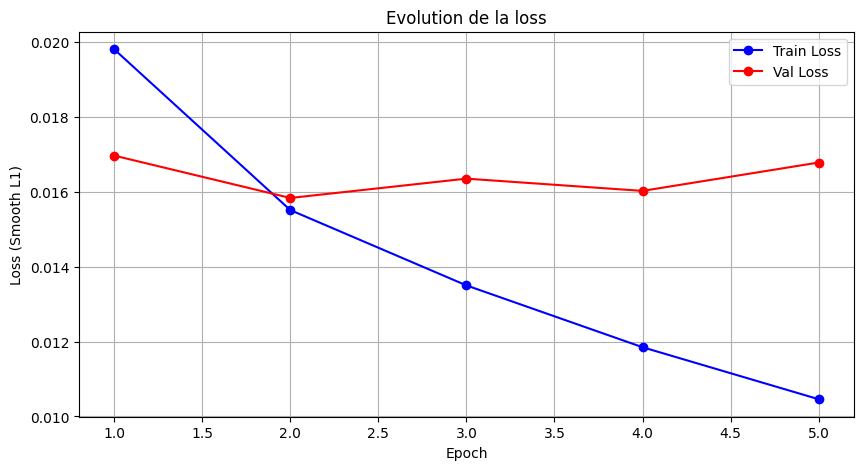


Bounding Box
Loss initiale: 0.0539
Loss finale:   0.0110
Amélioration:  0.0429 (79.5%)


In [93]:
# Recharger le modèle 
vit_bbox = vit_b_16(weights='IMAGENET1K_V1')
vit_bbox.to(device)

for param in vit_bbox.parameters():
    param.requires_grad = False

# Remplacer la tête : 1000 classes vers 4 coordonnées (xmin, ymin, xmax, ymax)
in_features = vit_bbox.heads.head.in_features
vit_bbox.heads.head = nn.Sequential(
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Linear(256, 4),
    nn.Sigmoid()  # Sortie entre 0 et 1 (coordonnées normalisées)
)
vit_bbox.to(device)

print("Modèle adapté pour la régression de bounding box")
print(f"Nouvelle tête: {vit_bbox.heads.head}")

# Compter les paramètres entraînables
total_params = sum(p.numel() for p in vit_bbox.parameters())
trainable_params = sum(p.numel() for p in vit_bbox.parameters() if p.requires_grad)
print(f"\nParamètres totaux: {total_params:,}")
print(f"Paramètres entraînables: {trainable_params:,}")
print(f"Paramètres gelés: {total_params - trainable_params:,}")

# Définir la loss et l'optimiseur
# Smooth L1 Loss 
criterion_bbox = nn.SmoothL1Loss()

# Adam 
optimizer_bbox = torch.optim.Adam(vit_bbox.heads.head.parameters(), lr=1e-3)

# fonction pour extraire et normaliser les bounding boxes
def get_normalized_bbox(targets, img_size=224):
    """
    Extrait la première bounding box et la normalise entre 0 et 1
    """
    bboxes = []
    for t in targets:
        bb = t['bndbox'][0]  # Prendre seulement la première bbox
        # Normaliser par la taille de l'image
        bbox_norm = [
            bb[0].item() / img_size,  # xmin
            bb[1].item() / img_size,  # ymin
            bb[2].item() / img_size,  # xmax
            bb[3].item() / img_size   # ymax
        ]
        bboxes.append(bbox_norm)
    return torch.tensor(bboxes, dtype=torch.float32)

# Calcul de la loss initiale
print("\n" + "=" * 50)
print("Loss initiale avant entraînement")
print("=" * 50)

vit_bbox.eval()
initial_loss_bbox = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        target_bbox = get_normalized_bbox(targets).to(device)
        
        outputs = vit_bbox(inputs)
        loss = criterion_bbox(outputs, target_bbox)
        
        initial_loss_bbox += loss.item() * inputs.size(0)
        count += inputs.size(0)

initial_loss_bbox = initial_loss_bbox / count
print(f"Loss initiale (bbox): {initial_loss_bbox:.4f}")

# Entraînement (5 époques)

print("\n" + "=" * 50)
print("Entraînement (5 époques)")
print("=" * 50)

epochs_bbox = 5
train_losses_bbox = []
val_losses_bbox = []

for epoch in range(epochs_bbox):
    # Entraînement
    vit_bbox.train()
    running_loss = 0.0
    count = 0
    
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        inputs = inputs.to(device)
        target_bbox = get_normalized_bbox(targets).to(device)
        
        optimizer_bbox.zero_grad()
        outputs = vit_bbox(inputs)
        loss = criterion_bbox(outputs, target_bbox)
        loss.backward()
        optimizer_bbox.step()
        
        running_loss += loss.item() * inputs.size(0)
        count += inputs.size(0)
        
        if batch_idx % 200 == 0:
            print(f"  Epoch {epoch+1}/{epochs_bbox} - Batch {batch_idx} - Loss: {loss.item():.4f}")
    
    train_loss = running_loss / count
    train_losses_bbox.append(train_loss)
    
    # Validation 
    vit_bbox.eval()
    val_loss = 0.0
    count = 0
    
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            target_bbox = get_normalized_bbox(targets).to(device)
            outputs = vit_bbox(inputs)
            loss = criterion_bbox(outputs, target_bbox)
            val_loss += loss.item() * inputs.size(0)
            count += inputs.size(0)
    
    val_loss = val_loss / count
    val_losses_bbox.append(val_loss)
    
    print(f"Epoch {epoch+1}/{epochs_bbox} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")
    print("-" * 40)

# 6. Loss finale
print("\n" + "=" * 60)
print("Loss après entraînement")
print("=" * 60)

vit_bbox.eval()
final_loss_bbox = 0.0
count = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        target_bbox = get_normalized_bbox(targets).to(device)
        outputs = vit_bbox(inputs)
        loss = criterion_bbox(outputs, target_bbox)
        final_loss_bbox += loss.item() * inputs.size(0)
        count += inputs.size(0)

final_loss_bbox = final_loss_bbox / count
print(f"Loss finale (bbox): {final_loss_bbox:.4f}")

# Visualisation de l'évolution de la loss

plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_bbox+1), train_losses_bbox, 'b-o', label='Train Loss')
plt.plot(range(1, epochs_bbox+1), val_losses_bbox, 'r-o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Smooth L1)')
plt.title('Evolution de la loss')
plt.legend()
plt.grid(True)
plt.show()

# Résumé
print("\n" + "=" * 60)
print("Bounding Box")
print("=" * 60)
print(f"Loss initiale: {initial_loss_bbox:.4f}")
print(f"Loss finale:   {final_loss_bbox:.4f}")
print(f"Amélioration:  {initial_loss_bbox - final_loss_bbox:.4f} ({((initial_loss_bbox - final_loss_bbox)/initial_loss_bbox)*100:.1f}%)")
print("=" * 60)

## Analyse des résultats

* L'apprentissage est immédiat, avec une forte chute de l'erreur dès la première époque, ce qui prouve que les caractéristiques extraites par le modèle sont déjà idéales pour la localisation.

* L'amélioration globale de près de 80% démontre que le modèle parvient à placer les boîtes avec une grande précision.

* La perte de validation atteint son minimum très vite, dès l'époque 2 et cesse de s'améliorer alors que l'entraînement continue de descendre, ce qui indique que le modèle a appris tout ce qu'il pouvait généraliser.

### Visualisation des Prédictions

Pour évaluer le modèle, nous affichons quelques images du set de test avec :
* En **Vert** : La vraie boîte annotée.
* En **Rouge** : La boîte prédite par le modèle.

Visualisation des prédictions de bounding boxes



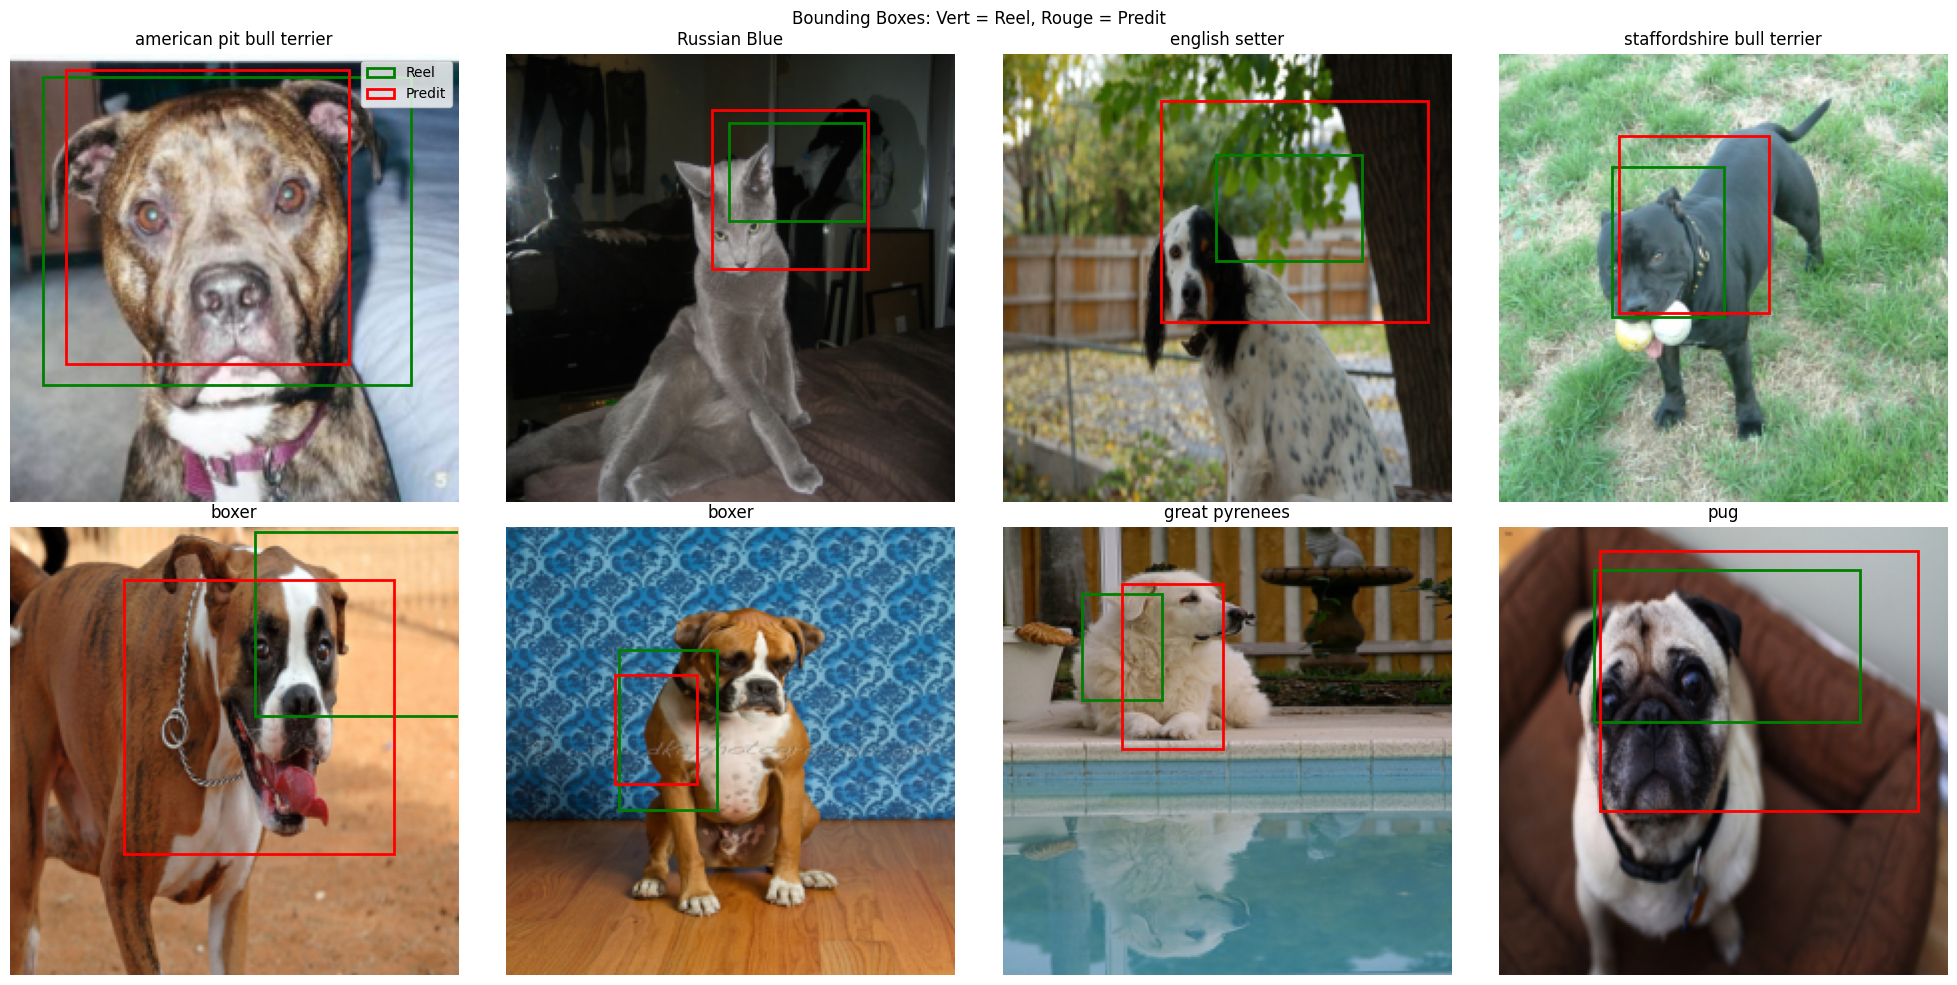

In [97]:
# Visualisation des prédictions de bounding boxes 
import matplotlib.patches as patches

print("Visualisation des prédictions de bounding boxes\n")

vit_bbox.eval()
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

# Collecter 8 images 
all_inputs = []
all_targets = []
all_preds = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        preds = vit_bbox(inputs)
        
        all_inputs.extend(inputs.cpu())
        all_targets.extend(targets)
        all_preds.extend(preds.cpu())

# Choisir 8 indices aléatoires
random_indices = np.random.choice(len(all_inputs), size=8, replace=False)

# Afficher les images 
for i, idx in enumerate(random_indices):
    ax = axes[i]
    
    # afficher l'image
    img = all_inputs[idx].numpy().transpose(1, 2, 0)
    ax.imshow(img)
    
    # Bounding box reelle : vert
    true_bbox = get_normalized_bbox([all_targets[idx]])[0] * 224
    xmin_t, ymin_t, xmax_t, ymax_t = true_bbox.numpy()
    rect_true = patches.Rectangle(
        (xmin_t, ymin_t), xmax_t - xmin_t, ymax_t - ymin_t,
        linewidth=2, edgecolor='green', facecolor='none', label='Reel'
    )
    ax.add_patch(rect_true)
    
    # Bounding box predite : rouge
    pred_bbox = all_preds[idx] * 224
    xmin_p, ymin_p, xmax_p, ymax_p = pred_bbox.numpy()
    rect_pred = patches.Rectangle(
        (xmin_p, ymin_p), xmax_p - xmin_p, ymax_p - ymin_p,
        linewidth=2, edgecolor='red', facecolor='none', label='Predit'
    )
    ax.add_patch(rect_pred)
    
    ax.set_title(f'{oxford_cat[all_targets[idx]["category"]]}')
    ax.axis('off')

# Legende
axes[0].legend(loc='upper right')
plt.suptitle('Bounding Boxes: Vert = Reel, Rouge = Predit')
plt.tight_layout()
plt.show()


## Analyse visuelle des prédictions

En regardant les images, le résultat est correct mais pas parfait :

*  Le modèle trouve bien l'animal et ne se trompe pas de zone.

* La boîte rouge est souvent un peu trop large ou décalée par rapport à la verte.

### Intersection over Union (IoU)

Pour savoir si une détection est bonne, on utilise l'IoU (Intersection over Union).

Nous calculons ici l'IoU moyen sur tout le jeu de test et affichons la distribution des scores.


IoU moyen: 0.3999 (39.99%)
IoU médian: 0.4194
IoU min: 0.0000
IoU max: 0.8992


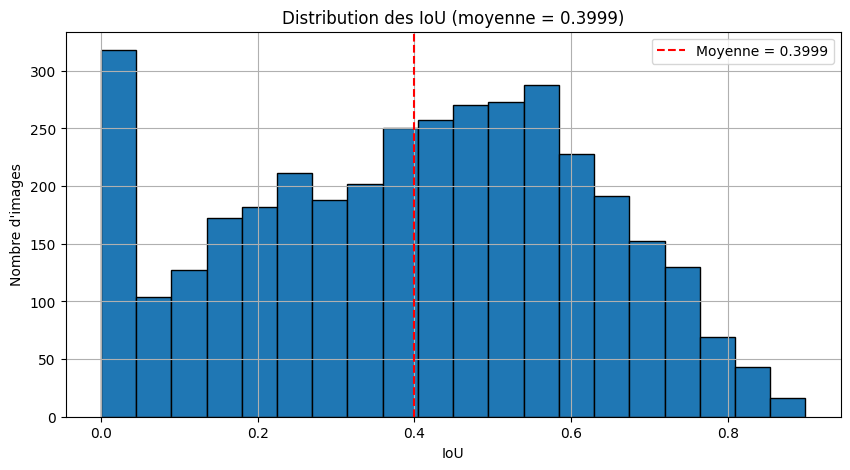

In [96]:
# Calcul de la métrique IoU (Intersection over Union)

def compute_iou(box1, box2):
    """
    Calcule l'IoU entre deux bounding boxes
    """
    # Intersection
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    
    # union
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    if union == 0:
        return 0
    return intersection / union

# Calculer IoU moyen sur le dataset de test
vit_bbox.eval()
ious = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        predictions = vit_bbox(inputs)
        
        for i in range(len(inputs)):
            pred_box = predictions[i].cpu().numpy()
            true_box = get_normalized_bbox([targets[i]])[0].numpy()
            iou = compute_iou(pred_box, true_box)
            ious.append(iou)

mean_iou = np.mean(ious)
print(f"\nIoU moyen: {mean_iou:.4f} ({mean_iou*100:.2f}%)")
print(f"IoU médian: {np.median(ious):.4f}")
print(f"IoU min: {np.min(ious):.4f}")
print(f"IoU max: {np.max(ious):.4f}")

# Histogramme des IoU
plt.figure(figsize=(10, 5))
plt.hist(ious, bins=20, edgecolor='black')
plt.xlabel('IoU')
plt.ylabel('Nombre d\'images')
plt.title(f'Distribution des IoU (moyenne = {mean_iou:.4f})')
plt.axvline(x=mean_iou, color='r', linestyle='--', label=f'Moyenne = {mean_iou:.4f}')
plt.legend()
plt.grid(True)
plt.show()

## Conclusion sur la détection

* Avec un score moyen de 0.40 le résultat est moyen. Cela confirme que le modèle repère la zone de l'animal, mais que la boîte n'est pas très précise.


* La variation des résultats de 0% à 90% est le point le plus important, car elle montre que le modèle n'est pas fiable sur toutes les images.